# A03-GN — GMM trên RFM (RFM thô → StandardScaler → PCA cố định 2 thành phần)

Thí nghiệm **A03-GN** (người chạy: Thuận, hạn nội bộ 17/11/2026) theo chiến lược model. So với A01, **chỉ cố định PCA = 2 thành phần** (PCA thực sự là đầu vào mô hình). Quy trình: làm sạch → RFM → RFM thô → StandardScaler → PCA cố định 2 thành phần → GMM.



## Params

In [ ]:
FEATURES = ["Recency", "Frequency", "Monetary"]
RANDOM_STATE = 42
N_INIT = 10               
MAX_ITER = 300
TOL = 1e-3
REG_COVAR = 1e-6
INIT_PARAMS = "kmeans"
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_CLUSTER_FRAC = 0.01     

## Import thư viện và đọc dữ liệu

In [ ]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())


DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 3)


,Recency,Frequency,Monetary
count,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95
std,99.98,7.64,8441.89
min,1.00,1.00,2.90
25%,18.00,1.00,301.52
50%,51.00,2.00,657.90
75%,143.00,5.00,1624.10
max,374.00,206.00,278748.02


**Nhận xét:** 4,327 khách, dùng chung file feature của nhóm. Monetary lệch phải rất mạnh (trung vị 657.9, max 278,748) nên tiền xử lý ảnh hưởng nhiều đến kết quả.

## Tiền xử lý

RFM thô → StandardScaler → PCA cố định 2 thành phần.

In [3]:
prep = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2, svd_solver="full", random_state=RANDOM_STATE)),
])
Z = prep.fit_transform(X.values)
print("Kích thước đầu vào mô hình:", Z.shape)
ev = prep["pca"].explained_variance_ratio_
print("Phương sai từng PC:", ev.round(4), "| giữ lại:", round(ev.sum(), 4))

Kích thước đầu vào mô hình: (4327, 2)
Phương sai từng PC: [0.5638 0.3016] | giữ lại: 0.8655


## Quét k × covariance_type

Chỉ số chọn là **BIC** (thấp hơn tốt hơn). Silhouette/DBI/CHI tính trên đầu vào mô hình, chỉ để tham khảo.

Chọn: full, k=5, BIC=7,795.3, Silhouette=0.1871, cụm nhỏ nhất=95


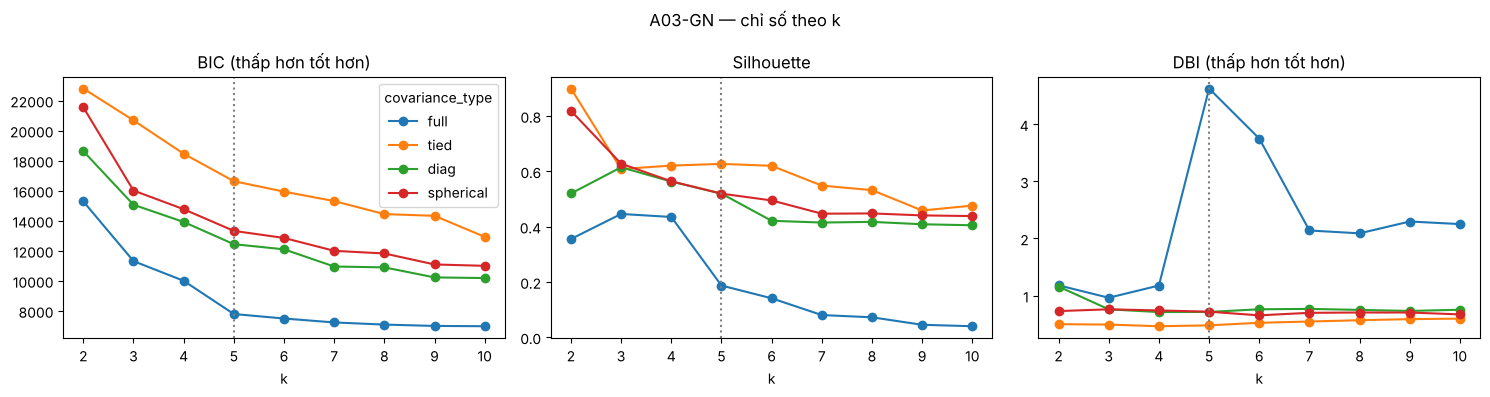

,covariance_type,k,BIC,AIC,Silhouette,DBI,CHI,min_cluster,converged
8,full,10,6982.8441,6606.8589,0.0401,2.2521,1051.2432,3,True
7,full,9,7002.8045,6665.0551,0.0453,2.2971,1289.9857,9,True
6,full,8,7091.6604,6792.1468,0.0723,2.0900,1225.6028,3,True
5,full,7,7234.9613,6973.6835,0.0805,2.1397,1349.9776,18,True
4,full,6,7496.5534,7273.5114,0.1411,3.7491,1152.8673,36,True
3,full,5,7795.3193,7610.5130,0.1871,4.6248,907.3436,95,True
2,full,4,10005.6767,9859.1062,0.4350,1.1762,1486.1631,124,True
26,diag,10,10188.5594,9876.3006,0.4049,0.7526,4915.7778,3,True
25,diag,9,10231.9712,9951.5755,0.4086,0.7317,4106.4342,6,True
24,diag,8,10900.2199,10651.6873,0.4172,0.7497,4411.4863,6,True


In [4]:
def sweep(Xs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = GaussianMixture(n_components=k, covariance_type=cov, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL,
                                 reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Xs)
            lab = gm.predict(Xs); sizes = np.bincount(lab, minlength=k)
            ok = len(np.unique(lab)) > 1
            rows.append({"covariance_type": cov, "k": k, "BIC": gm.bic(Xs), "AIC": gm.aic(Xs),
                         "Silhouette": silhouette_score(Xs, lab) if ok else np.nan,
                         "DBI": davies_bouldin_score(Xs, lab) if ok else np.nan,
                         "CHI": calinski_harabasz_score(Xs, lab) if ok else np.nan,
                         "min_cluster": int(sizes.min()), "converged": bool(gm.converged_)})
    return pd.DataFrame(rows)

def select(res, n):
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_CLUSTER_FRAC * n)]
    return ok.loc[ok["BIC"].idxmin()]

res = sweep(Z)
best = select(res, len(X))
print(f"Chọn: {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}, "
      f"Silhouette={best['Silhouette']:.4f}, cụm nhỏ nhất={int(best['min_cluster'])}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BIC", "Silhouette", "DBI"]):
    for cov in COV_TYPES:
        s = res[res["covariance_type"] == cov]
        ax.plot(s["k"], s[col], marker="o", label=cov)
    ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k"); ax.set_title(col + (" (thấp hơn tốt hơn)" if col in ("BIC", "DBI") else ""))
axes[0].legend(title="covariance_type")
plt.suptitle("A03-GN — chỉ số theo k"); plt.tight_layout()
plt.savefig(FIG / "gmm_metrics.png", dpi=150); plt.show()
res.sort_values("BIC").head(10).round(4)

**Nhận xét:** BIC thấp nhất trong các cấu hình hội tụ và có cụm ≥ 1% khách là `full`, k=5 (BIC 7,795.3); cụm nhỏ nhất 95 khách. Silhouette 0.1871, DBI 4.6248. Có 5 cấu hình BIC thấp hơn nhưng bị loại do cụm quá nhỏ (< 1%) hoặc không hội tụ. Silhouette thấp: GMM là mô hình xác suất, các cụm chồng lấn nên chỉ số này chỉ để tham khảo.

## Train mô hình cuối

In [5]:
GM_ARGS = dict(n_components=int(best["k"]), covariance_type=best["covariance_type"], n_init=N_INIT, max_iter=MAX_ITER,
               tol=TOL, reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE)
model = Pipeline([("prep", Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=2, svd_solver="full", random_state=RANDOM_STATE)),
    ])),
                  ("gmm", GaussianMixture(**GM_ARGS))]).fit(X.values)
gm = model["gmm"]
assert np.allclose(model["prep"].transform(X.values), Z)
labels = gm.predict(Z)
proba = gm.predict_proba(Z)
print("Hội tụ:", gm.converged_, "| số vòng EM:", gm.n_iter_)
print("Số khách mỗi cụm:", dict(enumerate(np.bincount(labels).tolist())))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4))

Hội tụ: True | số vòng EM: 16
Số khách mỗi cụm: {0: 1274, 1: 497, 2: 1695, 3: 95, 4: 766}
Silhouette: 0.1871 | DBI: 4.6248


## Hồ sơ cụm (trên RFM gốc, trung vị)

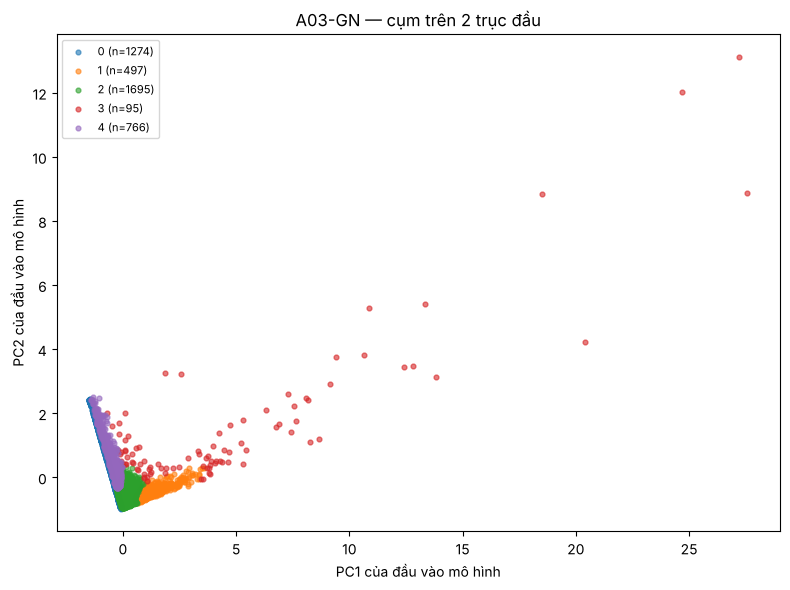

,customers,Recency,Frequency,Monetary,customer_share_pct,Monetary_share_pct
cluster,,,,,,
0,1274,147.0,1.0,213.4,29.4,3.5
1,497,9.0,11.0,3961.1,11.5,28.4
2,1695,27.0,3.0,981.9,39.2,26.0
3,95,18.0,19.0,16140.4,2.2,34.8
4,766,152.5,2.0,656.6,17.7,7.3


In [6]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"), Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum").round(1)

coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Z) if Z.shape[1] > 2 else Z
fig, ax = plt.subplots(figsize=(8, 6))
for c in sorted(np.unique(labels)):
    m = labels == c
    ax.scatter(coords[m, 0], coords[m, 1], s=12, alpha=0.6, marker="x" if c == -1 else "o", label=f"{c} (n={m.sum()})")
ax.set_xlabel("PC1 của đầu vào mô hình"); ax.set_ylabel("PC2 của đầu vào mô hình"); ax.legend(fontsize=8)
ax.set_title("A03-GN — cụm trên 2 trục đầu")
plt.tight_layout(); plt.savefig(FIG / "gmm_clusters_pca.png", dpi=150); plt.show()
prof

**Nhận xét:** Cụm 3 có Monetary trung vị cao nhất (16,140), gồm 95 khách (2.2%) nhưng chiếm 34.8% tổng Monetary. Cụm 2 đông nhất (39.2% khách, Recency trung vị 27 ngày).

## Đối chiếu với A01 (cùng tham số model)

In [ ]:

prep_parent = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.9, svd_solver="full", random_state=RANDOM_STATE)),
])
Zp = prep_parent.fit_transform(X.values)
lp = GaussianMixture(**GM_ARGS).fit(Zp).predict(Zp)
ari_parent = adjusted_rand_score(labels, lp)
same_dims = Zp.shape[1] == Z.shape[1]
same_geometry = same_dims and np.allclose(np.linalg.norm(Z[:300, None] - Z[None, :300], axis=2),
                                          np.linalg.norm(Zp[:300, None] - Zp[None, :300], axis=2), atol=1e-8)
print(f"A03: {Z.shape[1]} chiều | A01: {Zp.shape[1]} chiều")
print(f"ARI giữa nhãn A03 và nhãn A01 (cùng tham số): {ari_parent:.4f}")
print("Cùng hình học khoảng cách:", same_geometry)

A03: 2 chiều | A01: 3 chiều
ARI giữa nhãn A03 và nhãn A01 (cùng tham số): 0.3891
Cùng hình học khoảng cách: False


**Nhận xét:** ARI giữa A03 và A01 (cùng tham số) = 0.3891; số chiều đầu vào 2 so với 3. Nhãn khác nhiều: thay đổi tiền xử lý làm đổi phân cụm đáng kể.

## Lưu kết quả

In [9]:
res.to_csv(OUT / "gmm_a03_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels, "max_proba": proba.max(axis=1).round(4)}) \
    .to_csv(OUT / "gmm_a03_labels.csv", index=False)
joblib.dump(model, "gmm_a03_model.pkl")
params = {"experiment": "A03-GN", "features": FEATURES, "transform": None,
          "scaler": "StandardScaler", "pca": 2,
          "n_components": int(Z.shape[1]), "n_customers": int(len(X)),
          "pca_variance_kept": float(model["prep"]["pca"].explained_variance_ratio_.sum()),
          "covariance_type": best["covariance_type"], "k": int(best["k"]), "bic": float(best["BIC"]), "aic": float(best["AIC"]),
          "silhouette": float(best["Silhouette"]), "dbi": float(best["DBI"]), "chi": float(best["CHI"]),
          "min_cluster": int(best["min_cluster"]), "converged": bool(gm.converged_), "n_iter": int(gm.n_iter_),
          "gmm_params": {k: v for k, v in gm.get_params().items()},
          "ari_vs_parent_fixed_params": {"parent": "A01", "ari": float(ari_parent)}}
json.dump(params, open(OUT / "gmm_a03_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2, default=str)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['gmm_a03_grid.csv', 'gmm_a03_labels.csv', 'gmm_a03_params.json']


**Kết luận A03-GN:** GMM `full` k=5 (BIC 7,795.3) trên 2 chiều đầu vào. ARI với A01 (cùng tham số) = 0.3891. Silhouette giữa các cấu hình khác không gian đầu vào (số chiều, scaler) không so sánh trực tiếp được; dùng ARI và hồ sơ cụm trên RFM gốc để so sánh.